# Phase 2: DreamBooth with prior preservation

Each subject gets its own fine-tune of Stable Diffusion v1.5: 800 steps on its 4 to 6 photos with `a photo of zwx {class}`, plus the prior-preservation loss on 200 class images (`a photo of a {class}`, weight 1.0). Then the same 25 prompts x 4 samples as Phase 1, now with `zwx` in the prompt.

Every Phase 2 image reuses the seed of the Phase 1 image with the same prompt and sample number, so each pair starts from the same noise. The only difference is the fine-tune.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from configs.subjects import DOG_FIGURE_PROMPT_INDICES, SUBJECTS, prompt_rows, subject_by_name

REFERENCES_512 = ROOT / "data" / "references_512"
PHASE1 = ROOT / "phase1" / "outputs"
PHASE2 = ROOT / "phase2" / "samples"

phase1 = json.loads((ROOT / "phase1" / "metrics.json").read_text())
phase2 = json.loads((ROOT / "phase2" / "metrics.json").read_text())
PAPER = {"dino": 0.668, "clip_i": 0.803, "clip_t": 0.305}


def show_grid(items, ncols, figsize):
    nrows = (len(items) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = list(axes.ravel()) if hasattr(axes, "ravel") else [axes]
    for ax in axes:
        ax.axis("off")
    for ax, (image, title) in zip(axes, items):
        ax.imshow(image)
        ax.axis("off")
        if title:
            ax.set_title(title, fontsize=9)
    fig.tight_layout()
    plt.show()


## Scores

Same scorer as Phase 1: DINO and CLIP-I against the real photos of the same subject, CLIP-T against the prompt. For CLIP-T, Phase 2 uses the prompt without `zwx`, which is the exact text Phase 1 was scored with.


In [2]:
print(f"{'':18} {'DINO':>15} {'CLIP-I':>15} {'CLIP-T':>15}")
print(f"{'':18} {'P1':>7} {'P2':>7} {'P1':>7} {'P2':>7} {'P1':>7} {'P2':>7}")
rows = [("all 800", phase1, phase2)] + [
    (s["name"], phase1["subjects"][s["name"]], phase2["subjects"][s["name"]]) for s in SUBJECTS
]
for name, a, b in rows:
    print(
        f"{name:18} {a['dino']:7.3f} {b['dino']:7.3f} {a['clip_i']:7.3f} {b['clip_i']:7.3f}"
        f" {a['clip_t']:7.3f} {b['clip_t']:7.3f}"
    )
print(f"{'paper (SD)':18} {'':7} {PAPER['dino']:7.3f} {'':7} {PAPER['clip_i']:7.3f} {'':7} {PAPER['clip_t']:7.3f}")


                              DINO          CLIP-I          CLIP-T
                        P1      P2      P1      P2      P1      P2
all 800              0.351   0.648   0.732   0.830   0.329   0.306
dog                  0.205   0.744   0.694   0.835   0.330   0.305
dog2                 0.115   0.660   0.703   0.819   0.332   0.309
cat                  0.516   0.762   0.759   0.858   0.334   0.290
cat2                 0.506   0.751   0.740   0.842   0.328   0.299
backpack             0.334   0.541   0.777   0.841   0.327   0.316
clock                0.335   0.502   0.746   0.820   0.314   0.291
teapot               0.383   0.469   0.772   0.824   0.355   0.330
colorful_sneaker     0.416   0.752   0.664   0.805   0.311   0.305
paper (SD)                   0.668           0.803           0.305


## The dog, before and after

Top row is our dog after the 512 crop. Then, for each prompt, four pretrained images (Phase 1) and the four fine-tuned images with the same seeds (Phase 2).


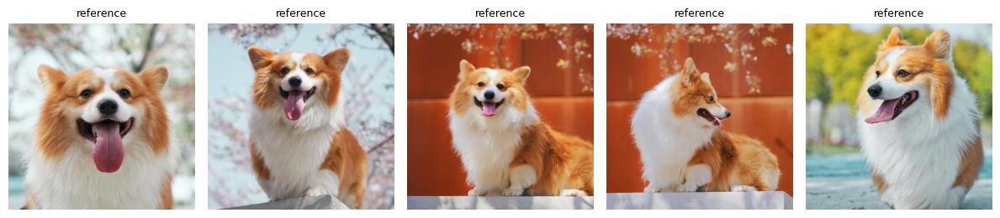

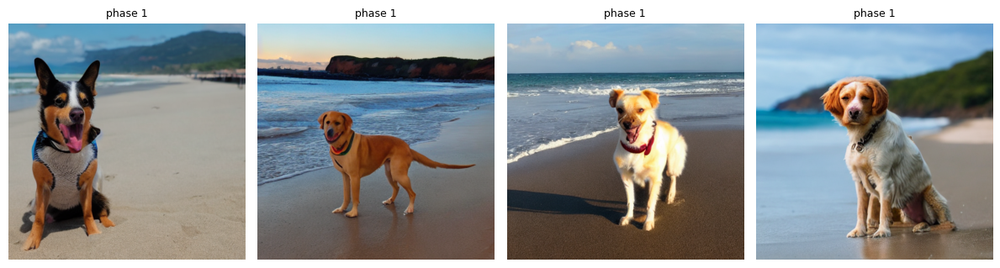

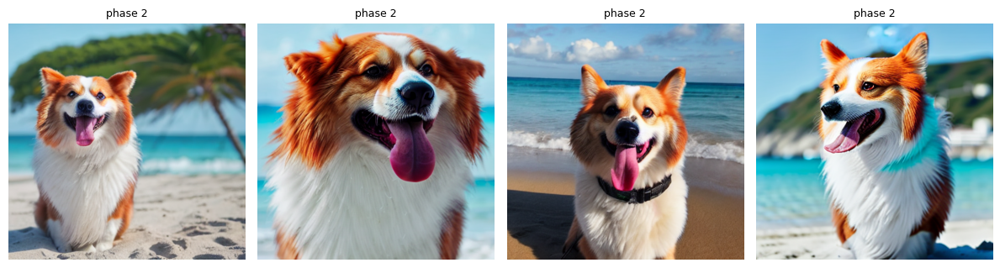

a dog on the beach  ->  a zwx dog on the beach


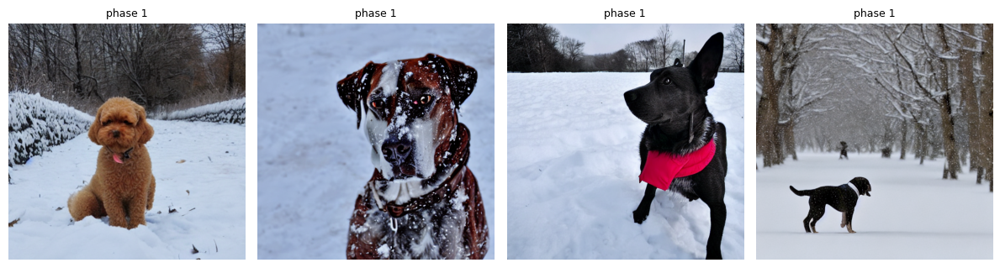

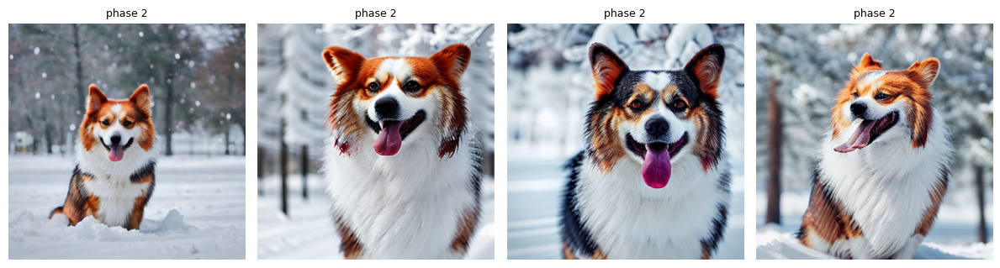

a dog in the snow  ->  a zwx dog in the snow


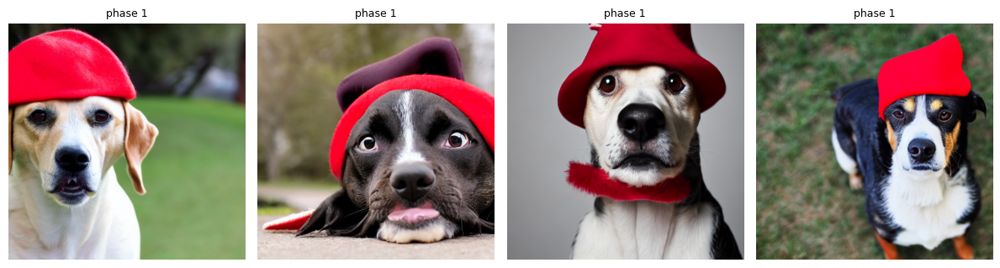

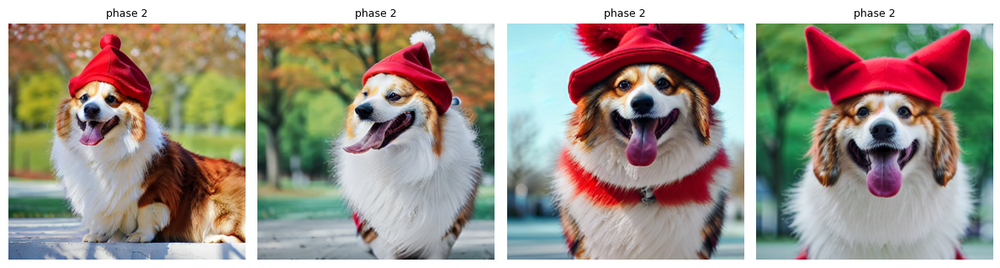

a dog wearing a red hat  ->  a zwx dog wearing a red hat


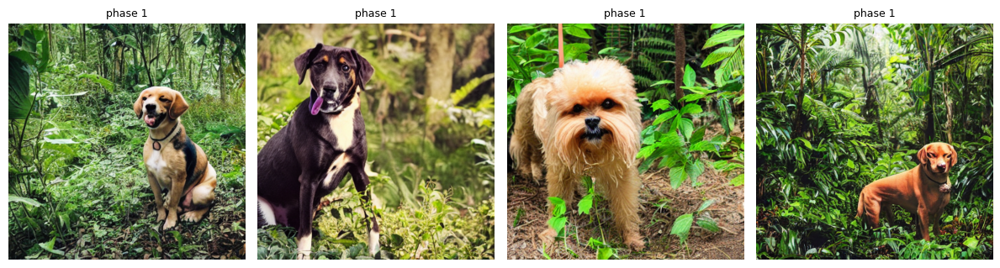

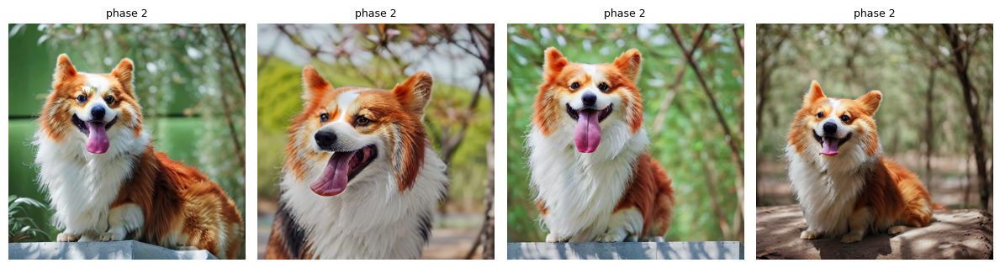

a dog in the jungle  ->  a zwx dog in the jungle


In [3]:
dog_refs = sorted((REFERENCES_512 / "dog").glob("*.png"))
show_grid([(Image.open(path), "reference") for path in dog_refs], ncols=5, figsize=(12, 2.8))

rows = prompt_rows(subject_by_name("dog"))
for index in DOG_FIGURE_PROMPT_INDICES:
    names = [f"p{index:02d}_s{sample}.png" for sample in range(4)]
    show_grid([(Image.open(PHASE1 / "dog" / name), "phase 1") for name in names], ncols=4, figsize=(12, 3.2))
    show_grid([(Image.open(PHASE2 / "dog" / name), "phase 2") for name in names], ncols=4, figsize=(12, 3.2))
    print(rows[index]["phase1"], " -> ", rows[index]["phase2"])


## Every subject, one prompt

One row per subject: a real photo, then the pretrained and the fine-tuned image for two prompts both lists share (jungle and beach), sample 0.


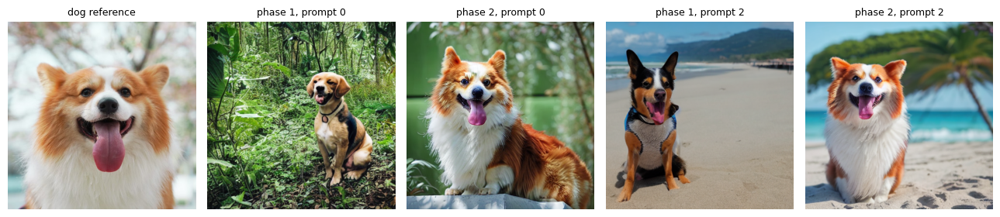

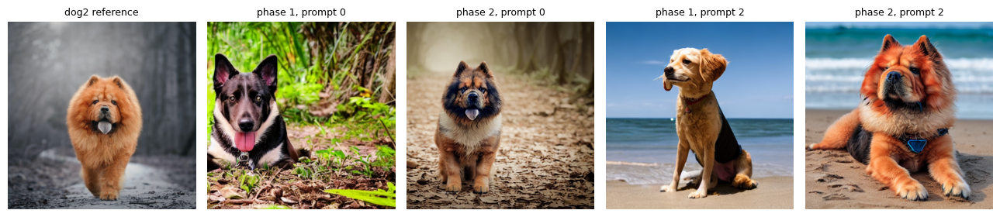

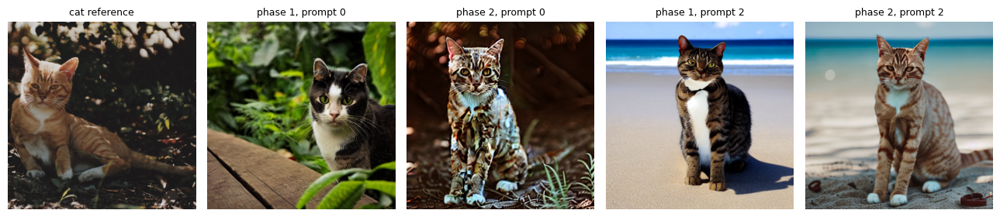

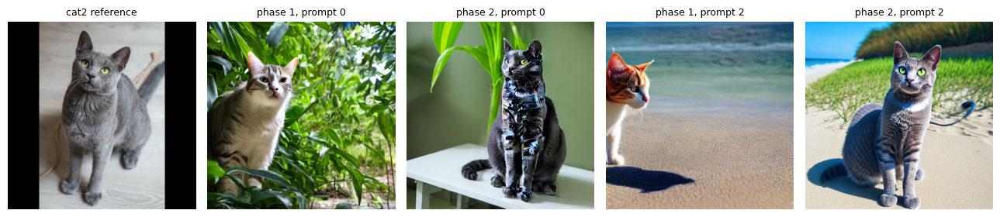

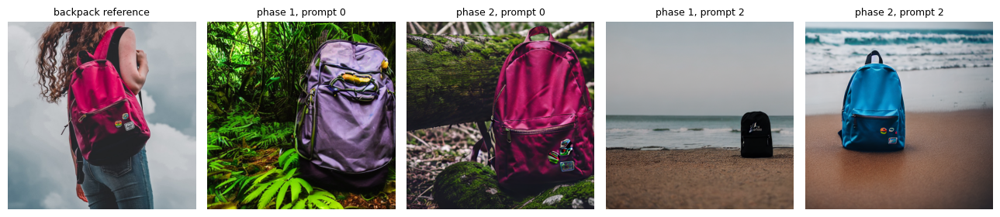

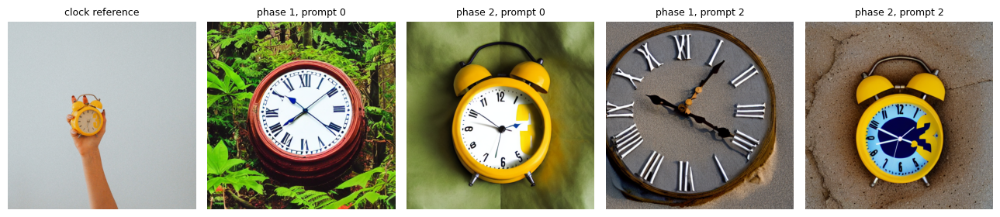

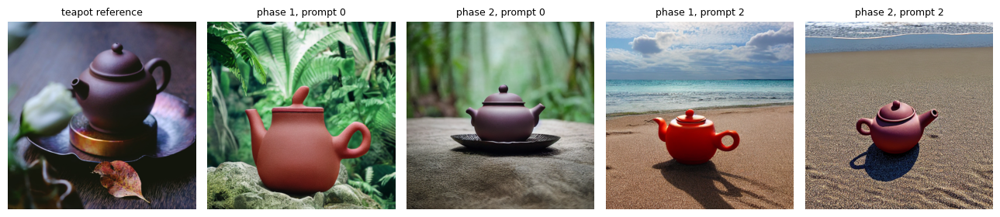

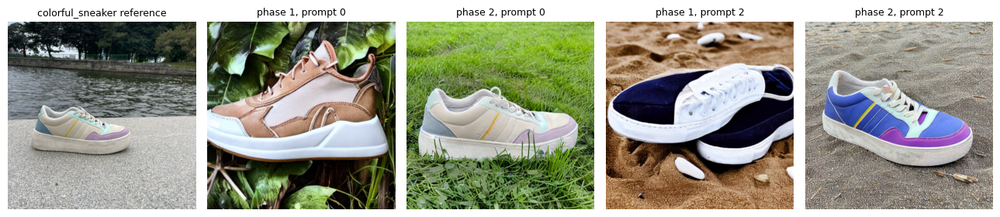

In [4]:
for subject in SUBJECTS:
    name = subject["name"]
    reference = sorted((REFERENCES_512 / name).glob("*.png"))[0]
    items = [(Image.open(reference), f"{name} reference")]
    for index in (0, 2):
        file = f"p{index:02d}_s0.png"
        items.append((Image.open(PHASE1 / name / file), f"phase 1, prompt {index}"))
        items.append((Image.open(PHASE2 / name / file), f"phase 2, prompt {index}"))
    show_grid(items, ncols=5, figsize=(13, 2.9))
